
## A2.1(a) Gillespie Simulation of the Stochastic SIS Model

The SIS model describes a population of size $N$ in which individuals are either susceptible or infectious. Infected individuals can transmit the disease to susceptible individuals, while infectious individuals can recover and become susceptible again.

Let $x$ denote the number of infectious individuals. The model has two possible events:

1. **Infection:** An infection occurs at rate
   $$w_1(x) = \frac{\beta x(N-x)}{N},$$
   increasing the number of infectious individuals by one.

2. **Recovery:** A recovery occurs at rate
   $$w_2(x) = \alpha x,$$
   decreasing the number of infectious individuals by one.

The Gillespie algorithm calculates the total event rate $W(x)=w_1(x)+w_2(x)$, samples the waiting time from an exponential distribution with mean $1/W(x)$, and selects the next event with probability proportional to its rate.

The implementation below separates event rate functions and state variations from the simulation algorithm, allowing the same function to be reused for other stochastic models.

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# Event rate functions:
def infection_rate(x, N, alpha, beta):
    return beta * x * (N - x) / N


def recovery_rate(x, N, alpha, beta):
    return alpha * x


# Event rates and corresponding state variations:
sis_rates = [infection_rate, recovery_rate]
sis_deltas = [1, -1]


# Generic Gillespie simulation
def gillespie(x0, T, rng, rates, deltas, params):
    t = 0.0
    x = x0

    times = [t]
    states = [x]

    while t < T:
        # Calculate the rate of each possible event
        event_rates = np.array([
            rate(x, **params) for rate in rates
        ], dtype=float)

        total_rate = np.sum(event_rates)

        # Stop if no events are possible
        if total_rate <= 0:
            break

        # Sample the waiting time until the next event
        dt = rng.exponential(scale=1.0 / total_rate)

        # Stop if the next event occurs beyond the time horizon
        if t + dt > T:
            break

        # Select an event with probability proportional to its rate
        probabilities = event_rates / total_rate
        event = rng.choice(len(rates), p=probabilities)

        # Update the time and state:
        t += dt
        x += deltas[event]

        times.append(t)
        states.append(x)

    return np.array(times), np.array(states)



## A2.1(b) Stochastic Trajectories for $N=500$

We simulate 50 independent stochastic SIS trajectories using Gillespie's algorithm with the parameters

$$
N=500,\quad \alpha=1,\quad \beta=1.5,\quad
x(0)=N/10=50,\quad T=20.
$$

We compare these trajectories with the deterministic solution of

$$
\frac{di}{dt}
=\frac{\beta i(N-i)}{N}-\alpha i,
\qquad i(0)=50.
$$

The stochastic trajectories are displayed using a step plot, while the deterministic solution is shown as a continuous curve.

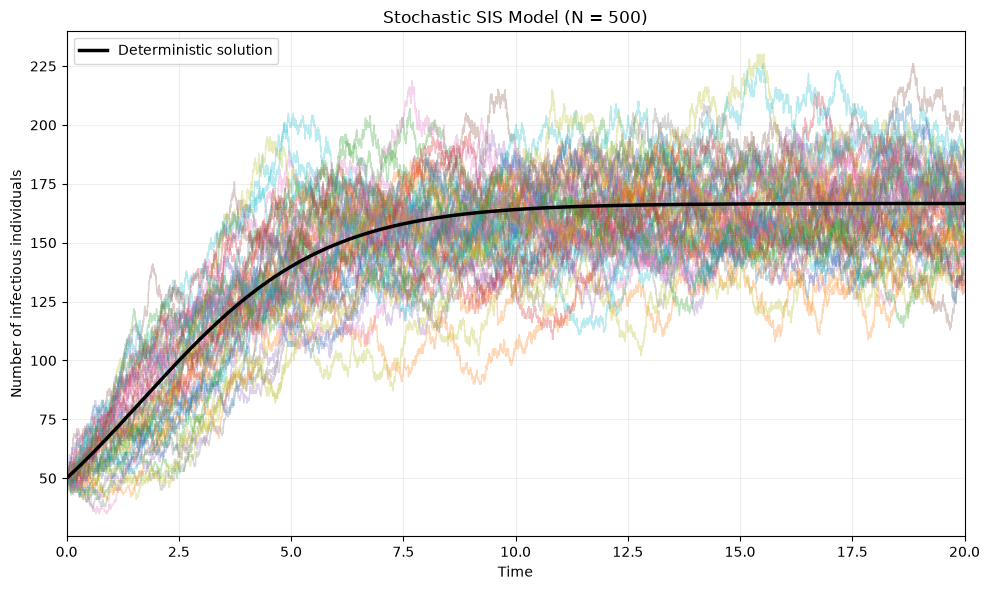

In [ ]:

# Model parameters:
N = 500
alpha = 1.0
beta = 1.5
T = 20.0
x0 = N // 10
n_trajectories = 50

params = {
    "N": N,
    "alpha": alpha,
    "beta": beta
}

# Generate 50 stochastic trajectories:
rng = np.random.default_rng(42)

trajectories = [
    gillespie(
        x0=x0,
        T=T,
        rng=rng,
        rates=sis_rates,
        deltas=sis_deltas,
        params=params
    )
    for _ in range(n_trajectories)
]


# Deterministic SIS model:
def sis_ode(t, i):
    return beta * i * (N - i) / N - alpha * i


t_eval = np.linspace(0, T, 1000)

solution = solve_ivp(
    sis_ode,
    (0, T),
    [x0],
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11
)


# Plot the stochastic and deterministic trajectories:
fig, ax = plt.subplots(figsize=(10, 6))

for times, states in trajectories:
    ax.step(
        times,
        states,
        where="post",
        alpha=0.3,
        linewidth=1
    )

ax.plot(
    solution.t,
    solution.y[0],
    color="black",
    linewidth=2.5,
    label="Deterministic solution"
)

ax.set_xlabel("Time")
ax.set_ylabel("Number of infectious individuals")
ax.set_title("Stochastic SIS Model (N = 500)")
ax.set_xlim(0, T)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


### Discussion

The stochastic trajectories fluctuate around the deterministic solution due to the randomness of infection and recovery events. The deterministic solution shows the overall trend of the infectious population, while individual stochastic trajectories may deviate from it. The deterministic solution approaches a positive equilibrium of $N(1-\alpha/\beta) = 166.67$ infectious individuals. In contrast, stochastic trajectories may eventually reach extinction if the number of infectious individuals becomes zero. Since zero is an absorbing state, no further infections can occur after extinction. These results illustrate the effect of random fluctuations on population dynamics.